# Comparação entre Random Forest e XGBoost

Os seis painéis e as matrizes abaixo leem os artefatos do run selecionado. O treino gera as figuras, tabelas e metadados usados também no MLflow.

Há cinco folds externos estratificados no TRAIN, com a mesma divisão para os dois modelos. Cada fold externo contém uma GridSearchCV de três folds que seleciona por F1 macro. Na base completa, exames com vetores idênticos ficam no mesmo grupo em todas as divisões. A classe de maior probabilidade determina a decisão.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN_ID = None  # None escolhe a execução completa mais recente com os dois modelos.

prefix = "gridsearch_cv"
manifest_name = f"{prefix}_manifest.json"
runs_dir = ROOT / "reports" / "runs"
expected_models = {"random_forest", "xgboost"}
if RUN_ID is None:
    candidates = []
    for path in runs_dir.glob(f"*/experiments/{manifest_name}"):
        candidate = json.loads(path.read_text(encoding="utf-8"))
        if set(candidate["models"]) == expected_models:
            candidates.append(candidate)
    if not candidates:
        raise FileNotFoundError("Gere os artefatos com python -m saude_fetal.train")
    manifest = max(candidates, key=lambda item: item["created_at"])
    run_id = manifest["parent_run_id"]
else:
    run_id = RUN_ID
    manifest = json.loads((runs_dir / run_id / "experiments" / manifest_name).read_text(encoding="utf-8"))
    if set(manifest["models"]) != expected_models:
        raise ValueError("Selecione um run com Random Forest e XGBoost.")

run_dir = runs_dir / run_id
metrics_dir = run_dir / "metrics"
figures_dir = run_dir / "figures"
results = pd.read_csv(metrics_dir / f"{prefix}_results.csv")
model_labels = {"random_forest": "Random Forest", "xgboost": "XGBoost"}
results["Modelo"] = results["model"].map(model_labels)
print(f"Run {run_id} · MLflow {manifest['tracking_backend']} · {manifest['created_at']}")
dataset = manifest['dataset'].get('name', 'fetal_health_reduced')
splitter = 'StratifiedGroupKFold' if manifest.get('group_duplicate_features') else 'StratifiedKFold'
print(f"Base {dataset} · {len(manifest.get('features', [])) or 4} features · {splitter}")

def show_figure(suffix):
    display(Image(filename=str(figures_dir / f"{prefix}_{suffix}.png")))

Run 1434549ebc3e47b1bb14499acbc9a75b · MLflow local · 2026-11-19T23:46:17.936423+00:00
Base fetal_health_full · 21 features · StratifiedGroupKFold


## Comparação na validação externa

F1 macro dá o mesmo peso às três classes. As barras de erro representam o desvio-padrão entre os cinco folds, em uma escala de 0 a 1. Recall patológico indica quantos registros dessa classe foram recuperados na validação.

,F1 macro,DP F1 macro,Recall macro,Precision macro,Recall patológico,Precision patológica
Modelo,,,,,,
XGBoost,0.922,0.021,0.913,0.933,0.936,0.944
Random Forest,0.889,0.021,0.889,0.898,0.900,0.927


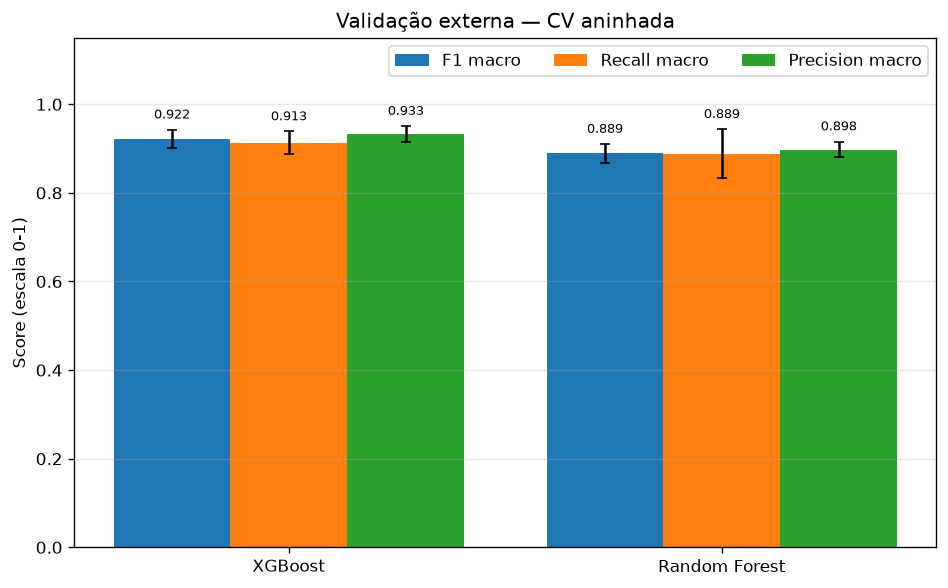

**XGBoost** liderou pelo F1 macro médio em **3.25 pontos percentuais** sobre Random Forest nesta CV. O recall patológico médio foi 93.6% e 90.0%, respectivamente.

In [2]:
summary_columns = {
    "cv_f1_macro_mean": "F1 macro",
    "cv_f1_macro_std": "DP F1 macro",
    "cv_recall_macro_mean": "Recall macro",
    "cv_precision_macro_mean": "Precision macro",
    "cv_recall_patologico_mean": "Recall patológico",
    "cv_precision_patologico_mean": "Precision patológica",
}
display(results.set_index("Modelo")[list(summary_columns)].rename(columns=summary_columns).round(3))
show_figure("model_comparison_f1_recall_precision")
best, second = results.iloc[0], results.iloc[1]
gap_pp = 100 * (best["cv_f1_macro_mean"] - second["cv_f1_macro_mean"])
display(Markdown(
    f"**{best['Modelo']}** liderou pelo F1 macro médio em **{gap_pp:.2f} pontos percentuais** "
    f"sobre {second['Modelo']} nesta CV. O recall patológico médio foi "
    f"{best['cv_recall_patologico_mean']:.1%} e {second['cv_recall_patologico_mean']:.1%}, respectivamente."
))

## Dispersão por fold e diferença entre treino e validação

As linhas usam os mesmos folds externos. O score de treino é medido nas amostras que ajustaram o pipeline de cada fold. Compare a diferença dentro do fold para investigar sobreajuste.

Random Forest               ...      XGBoost                      
     train_f1_macro val_f1_macro  ... val_f1_macro val_recall_patologico
fold                              ...                                   
1             0.984        0.894  ...        0.921                 0.929
2             0.960        0.916  ...        0.932                 0.964
3             0.959        0.898  ...        0.950                 0.929
4             0.982        0.876  ...        0.897                 0.857
5             0.984        0.861  ...        0.906                 1.000

[5 rows x 6 columns]

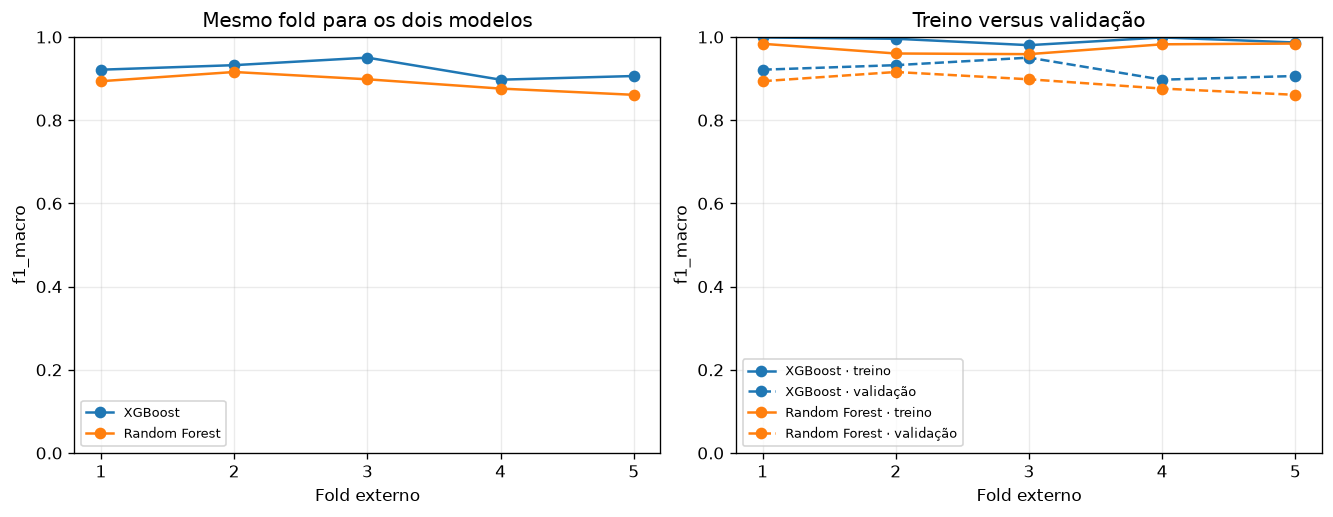

In [3]:
fold_tables = {}
for model, label in model_labels.items():
    folds = pd.read_csv(metrics_dir / f"{prefix}_{model}_fold_metrics.csv")
    fold_tables[label] = folds.set_index("fold")[["train_f1_macro", "val_f1_macro", "val_recall_patologico"]]
display(pd.concat(fold_tables, axis=1).round(3))
show_figure("fold_diagnostics")

## Diagnóstico por classe com predições OOF

Cada exame do TRAIN contribui com uma predição feita em seu fold externo de validação. As matrizes mostram contagens e proporções normalizadas pela classe real.

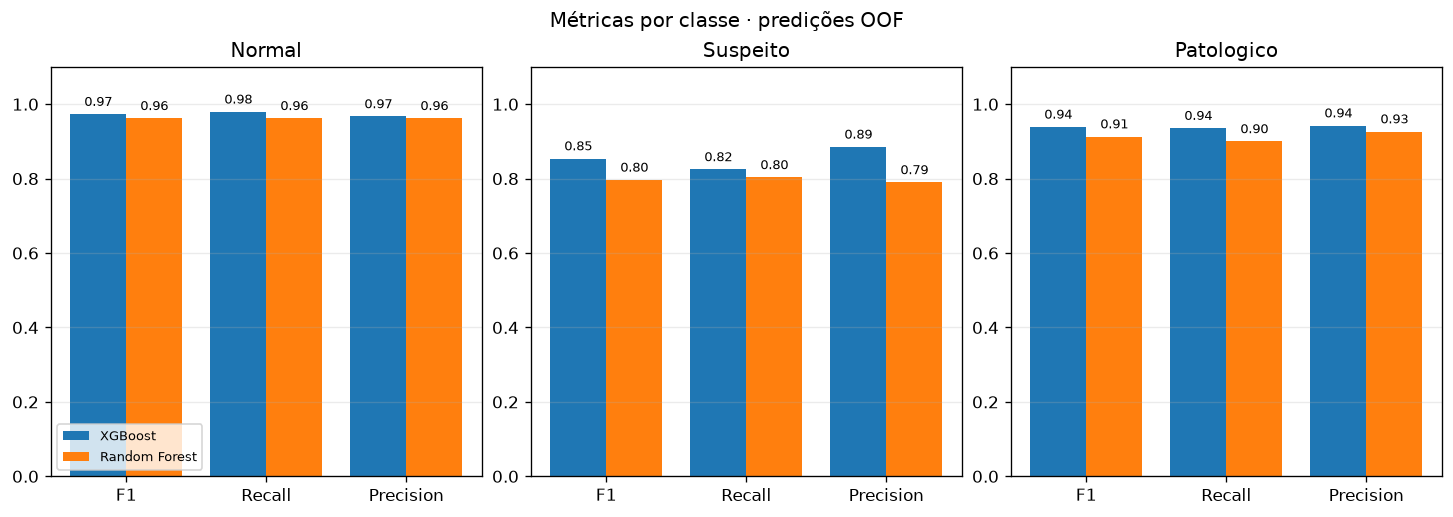

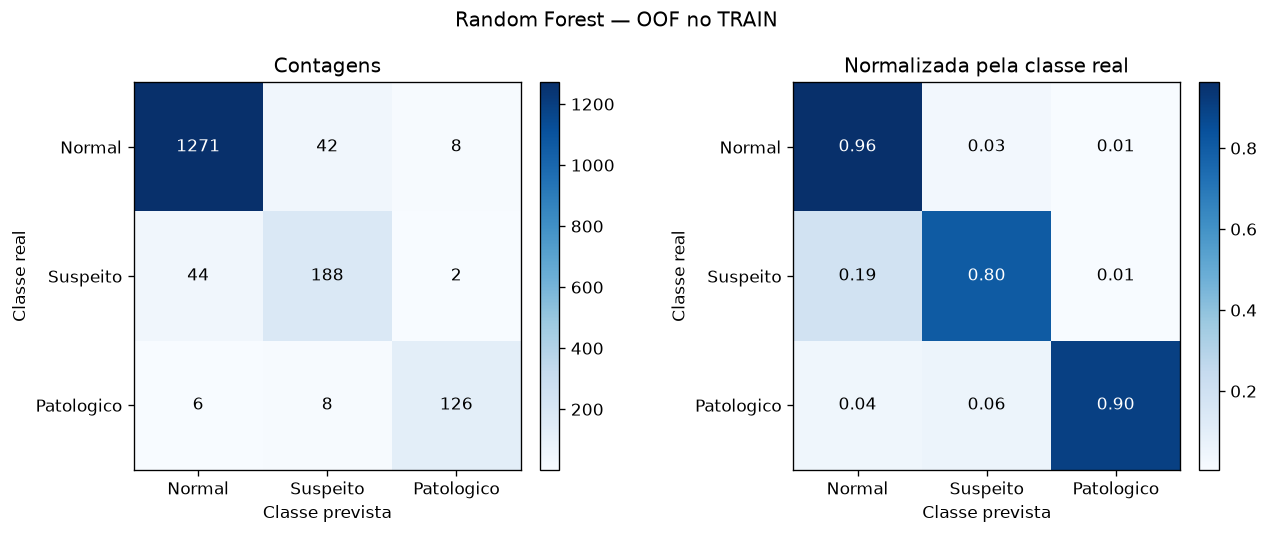

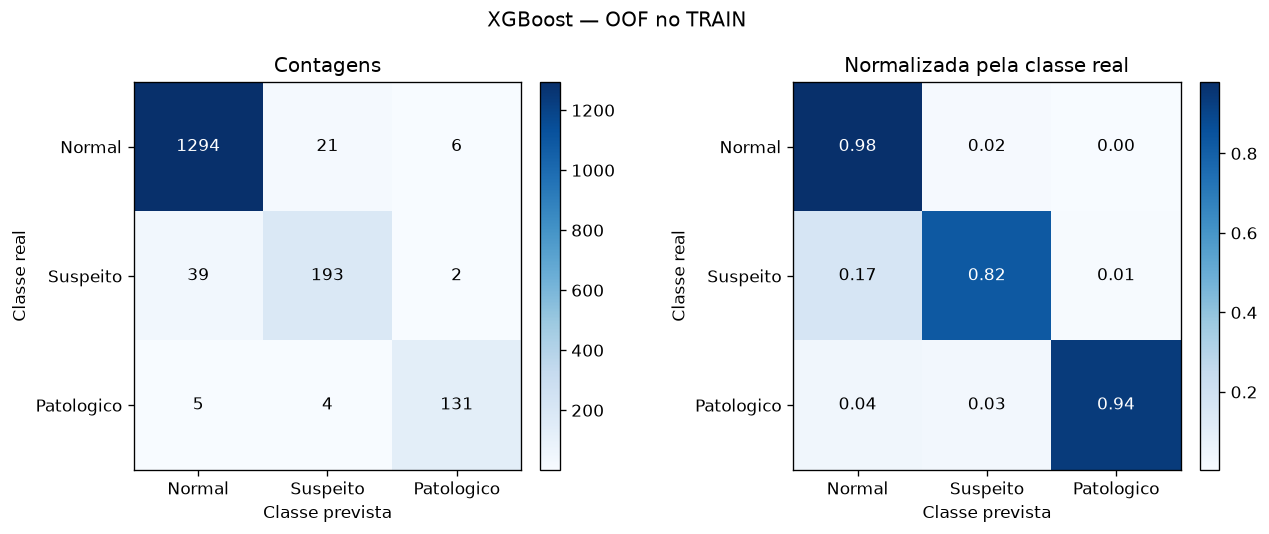

In [4]:
show_figure("oof_class_metrics")
for model in model_labels:
    show_figure(f"{model}_confusion_oof")

## Qualidade dos scores fora da amostra

As curvas tratam cada classe contra as demais. A linha pontilhada da curva precision–recall indica a prevalência, e AP resume a curva por incrementos de recall. A distribuição e o gráfico de calibração examinam o score patológico nos registros OOF.

,oof_ap_normal,oof_ap_suspeito,oof_ap_patologico,oof_roc_auc_normal,oof_roc_auc_suspeito,oof_roc_auc_patologico,oof_log_loss
Modelo,,,,,,,
XGBoost,0.995,0.908,0.972,0.983,0.976,0.994,0.147
Random Forest,0.995,0.878,0.974,0.982,0.970,0.996,0.186


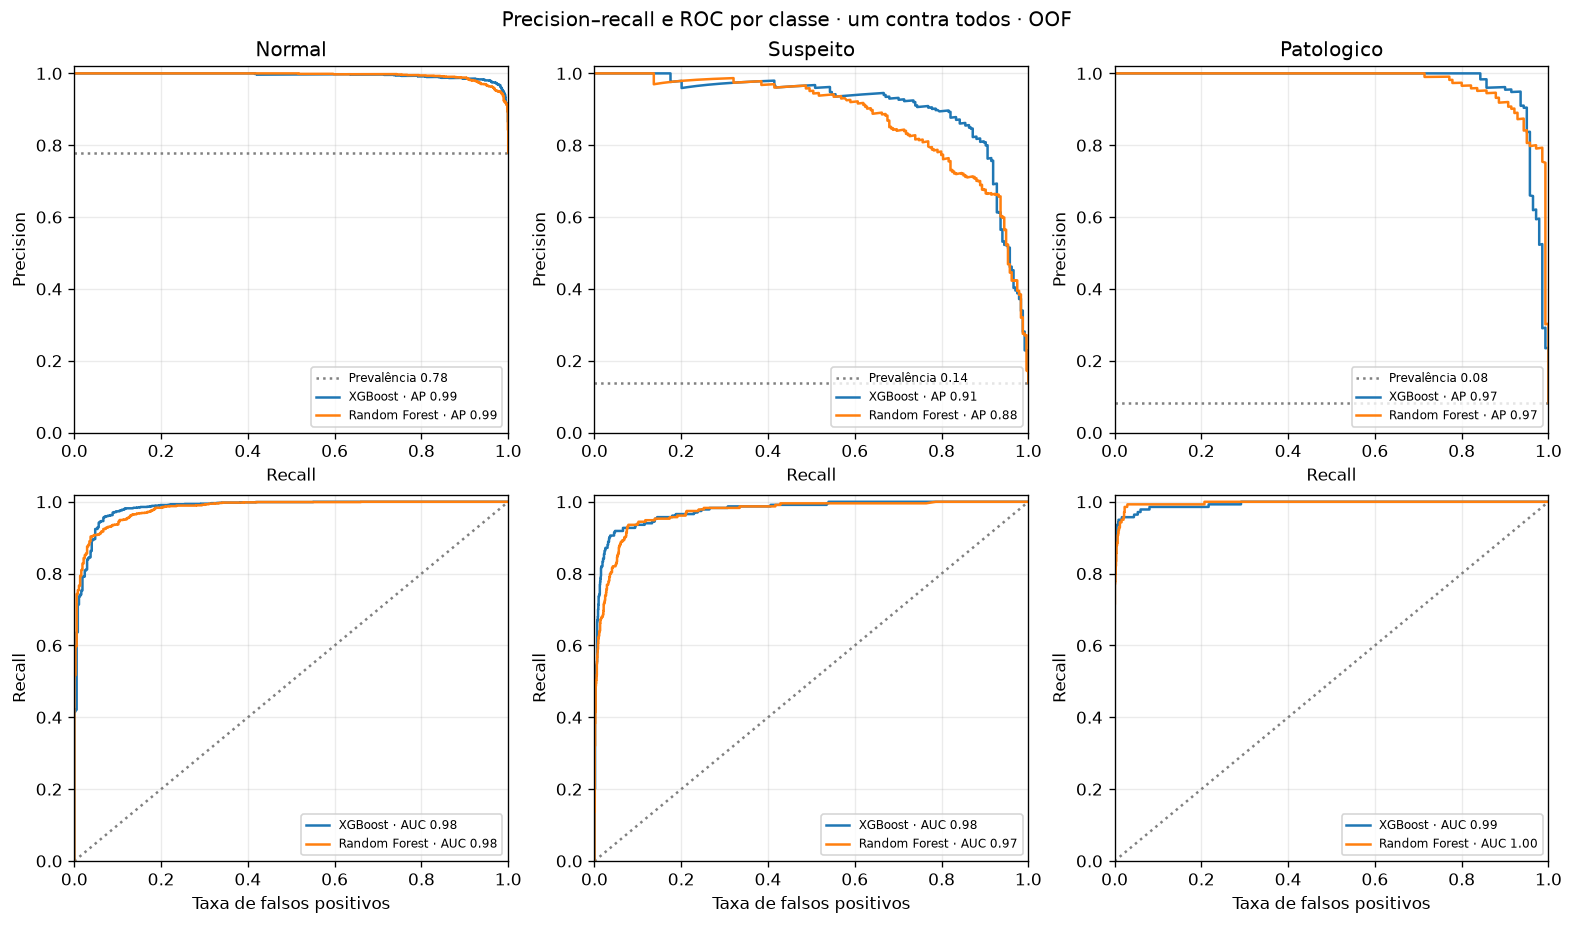

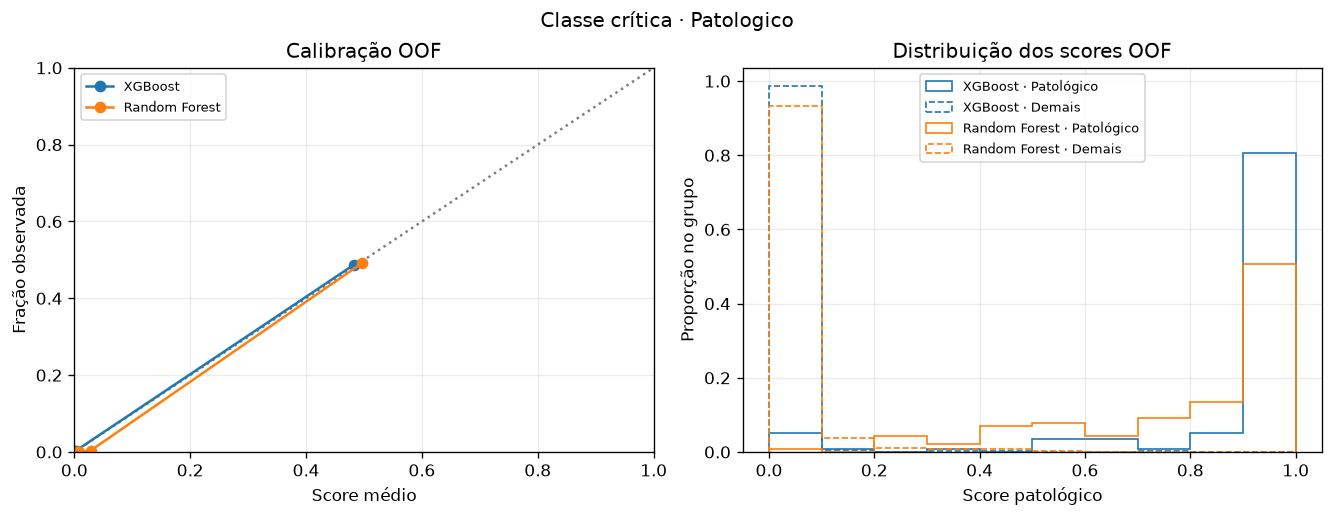

**Random Forest** teve a maior AP patológica OOF (0.974). A AP usa a ordenação de todos os scores. O recall da tabela inicial mede a decisão pela classe de maior score.

In [5]:
probability_metrics = ["oof_ap_normal", "oof_ap_suspeito", "oof_ap_patologico",
                       "oof_roc_auc_normal", "oof_roc_auc_suspeito", "oof_roc_auc_patologico", "oof_log_loss"]
display(results.set_index("Modelo")[probability_metrics].round(3))
show_figure("oof_pr_roc")
show_figure("oof_critical_probabilities")
best_ap = results.loc[results["oof_ap_patologico"].idxmax()]
display(Markdown(
    f"**{best_ap['Modelo']}** teve a maior AP patológica OOF "
    f"({best_ap['oof_ap_patologico']:.3f}). A AP usa a ordenação de todos os scores. "
    "O recall da tabela inicial mede a decisão pela classe de maior score."
))

## GridSearchCV no TRAIN completo e refit

Após a estimativa externa, uma nova busca de três folds sobre todo o TRAIN seleciona a configuração do pipeline final de cada família. A faixa sombreada marca o candidato selecionado. Em caso de empate de F1 macro, vale o primeiro candidato na ordem da grade. Os CSVs de cada run incluem também os resultados das buscas internas dos cinco folds externos.

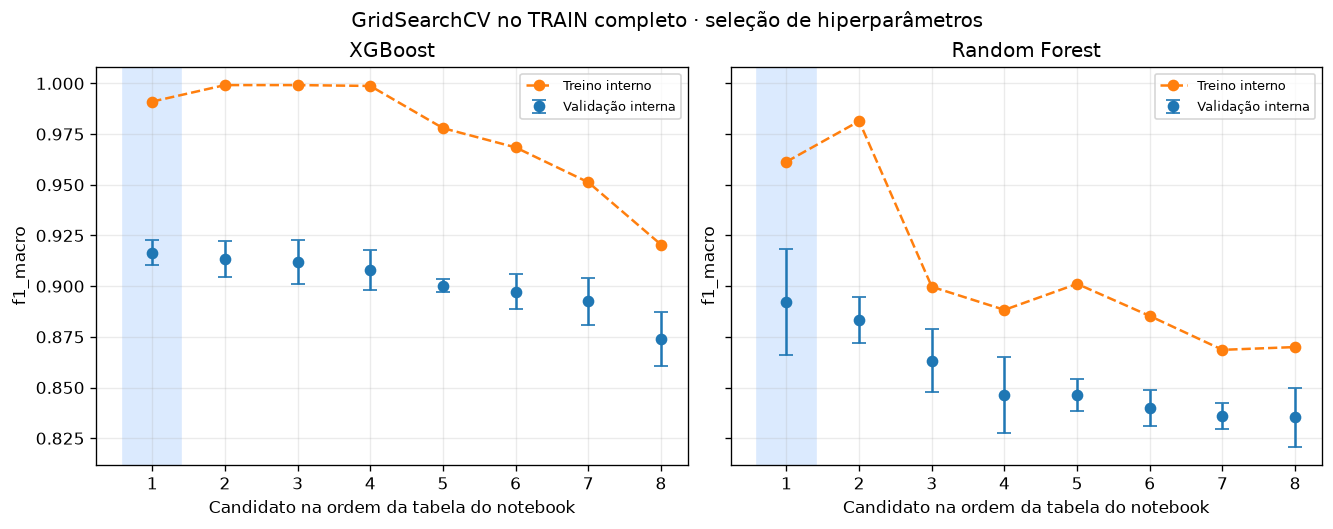

### Random Forest

,class_weight,max_depth,min_samples_leaf,mean_test_f1_macro,std_test_f1_macro,mean_test_recall_patologico
Candidato,,,,,,
1,balanced,NaN,2,0.892,0.026,0.928
2,None,NaN,2,0.883,0.011,0.864
3,balanced,NaN,8,0.863,0.016,0.914
4,balanced,5.0,2,0.846,0.019,0.864
5,None,NaN,8,0.846,0.008,0.757
6,None,5.0,2,0.840,0.009,0.764
7,None,5.0,8,0.836,0.006,0.743
8,balanced,5.0,8,0.835,0.015,0.872


### XGBoost

,learning_rate,max_depth,n_estimators,mean_test_f1_macro,std_test_f1_macro,mean_test_recall_patologico
Candidato,,,,,,
1,0.15,2,200,0.917,0.006,0.929
2,0.15,4,200,0.913,0.009,0.929
3,0.15,4,100,0.912,0.011,0.929
4,0.05,4,200,0.908,0.010,0.929
5,0.05,4,100,0.900,0.003,0.929
6,0.15,2,100,0.897,0.009,0.893
7,0.05,2,200,0.893,0.012,0.893
8,0.05,2,100,0.874,0.013,0.850


,train_refit_f1_macro,best_params,run_id
Modelo,,,
XGBoost,0.978331,"{""learning_rate"": 0.15, ""max_depth"": 2, ""n_est...",e74206fabeb343a789e79773f7314dbb
Random Forest,0.961698,"{""class_weight"": ""balanced"", ""max_depth"": null...",14a09290ed3b4897bf54ead9b02b209a


In [6]:
show_figure("grid_rank")
for model, label in model_labels.items():
    display(Markdown(f"### {label}"))
    grid = pd.read_csv(metrics_dir / f"{prefix}_{model}_grid_results.csv")
    params = pd.json_normalize(grid["params"].map(json.loads))
    scores = grid[["mean_test_f1_macro", "std_test_f1_macro", "mean_test_recall_patologico"]]
    candidates = params.join(scores.round(3))
    candidates.index = pd.RangeIndex(1, len(candidates) + 1, name="Candidato")
    display(candidates)
display(results.set_index("Modelo")[["train_refit_f1_macro", "best_params", "run_id"]])

## Avaliação no TEST

O TEST é reservado até o congelamento da receita. A comparação estima o desempenho nas partições do TRAIN. A ausência de identificadores de pacientes limita a avaliação da independência entre exames.